The datatab.net "Medical" example loads its data client-side via JavaScript, so it
could not be scraped directly. This notebook instead uses a representative synthetic
dataset generated for the same scenario: predicting whether a patient is susceptible
to a disease from Age, BMI, Blood Pressure and Cholesterol.

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
import seaborn as sn

In [2]:
rng = np.random.default_rng(42)
n = 200

age = rng.integers(20, 80, n)
bmi = rng.normal(26, 4, n).round(1)
blood_pressure = rng.normal(120, 15, n).round(0)
cholesterol = rng.normal(200, 30, n).round(0)

logit = (
    -12
    + 0.06 * age
    + 0.15 * bmi
    + 0.03 * blood_pressure
    + 0.02 * cholesterol
    + rng.normal(0, 1, n)
)
prob = 1 / (1 + np.exp(-logit))
disease = (prob > 0.5).astype(int)

data = pd.DataFrame({
    'Age': age,
    'BMI': bmi,
    'BloodPressure': blood_pressure,
    'Cholesterol': cholesterol,
    'Disease': disease,
})
data.to_csv('medical.csv', index=False)
data.head()

,Age,BMI,BloodPressure,Cholesterol,Disease
0,25,27.6,94.0,140.0,0
1,66,22.4,125.0,155.0,1
2,59,24.5,146.0,241.0,1
3,46,31.2,97.0,227.0,1
4,45,24.6,133.0,178.0,1


In [3]:
data.isnull().sum()

Age              0
BMI              0
BloodPressure    0
Cholesterol      0
Disease          0
dtype: int64

In [4]:
features = ['Age', 'BMI', 'BloodPressure', 'Cholesterol']
x = data[features]
y = data['Disease']

In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=5)

In [6]:
model = LogisticRegression(solver='lbfgs', max_iter=1000)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

[[ 3  2]
 [ 1 34]]
Accuracy: 0.925


<Axes: xlabel='Predicted', ylabel='Actual'>

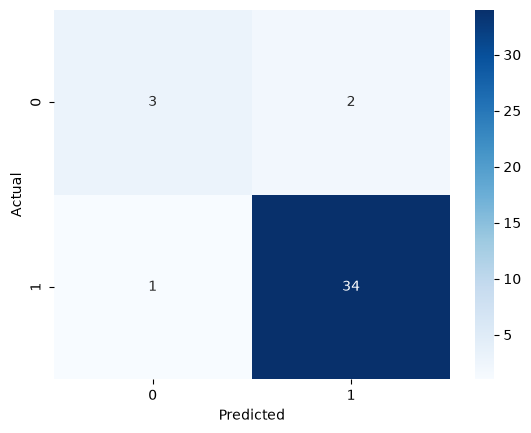

In [7]:
conf_matrix = metrics.confusion_matrix(y_test, y_pred)
print(conf_matrix)

accuracy_score = metrics.accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy_score)

conf_mat = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
sn.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')